In [368]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import  roc_auc_score, roc_curve
from sklearn.metrics import classification_report

In [369]:
file = pd.read_csv('credit_risk_dataset.csv')

In [370]:
file.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [371]:
file.isna().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [372]:
print(f"Ratio of employement length missing: {(file['person_emp_length'].isna().sum() / len(file))*100}%")
print(f"Ratio of loan interest rate missing: {(file['loan_int_rate'].isna().sum() / len(file))*100}%")

Ratio of employement length missing: 2.7469997851508547%
Ratio of loan interest rate missing: 9.563856235229121%


In [373]:
file.duplicated().sum()

165

In [374]:
file = file.drop_duplicates()

In [375]:
file.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32416.0,27.747008,6.354100,20.00,23.00,26.00,30.00,144.00
person_income,32416.0,66091.640826,62015.580269,4000.00,38542.00,55000.00,79218.00,6000000.00
person_emp_length,31529.0,4.790510,4.145490,0.00,2.00,4.00,7.00,123.00
loan_amnt,32416.0,9593.845632,6322.730241,500.00,5000.00,8000.00,12250.00,35000.00
loan_int_rate,29321.0,11.017265,3.241680,5.42,7.90,10.99,13.47,23.22
loan_status,32416.0,0.218688,0.413363,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32416.0,0.170250,0.106812,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32416.0,5.811297,4.059030,2.00,3.00,4.00,8.00,30.00


In [376]:
new_names = {
    "person_age": "Age",
    "person_income": "Annual_Income",
    "person_home_ownership": "Home_ownership",
    "person_emp_length": "Employment_length_years",
    "loan_intent": "Loan_intent",
    "loan_grade": "Loan_grade",
    "loan_amnt": "Loan_amount",
    "loan_int_rate": "Interest_rate",
    "loan_status": "Loan_status", # (0 is non default 1 is default) #Target
    "loan_percent_income": "Percent_income",
    "cb_person_default_on_file": "Historical_default",
    "cb_person_cred_hist_length": "Credit_history_length",
}

In [377]:
file = file.rename(columns=new_names)

In [378]:
file

,Age,Annual_Income,Home_ownership,Employment_length_years,Loan_intent,Loan_grade,Loan_amount,Interest_rate,Loan_status,Percent_income,Historical_default,Credit_history_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [379]:
numerical = file.select_dtypes(include=[int,float])
categorical = file.select_dtypes(include='object')

In [380]:
categorical = categorical.drop(columns='Historical_default')

In [381]:
label_hd = {'N':0, 'Y':1}
file['Historical_default'] = file['Historical_default'].map(label_hd)

In [382]:
numerical

,Age,Annual_Income,Employment_length_years,Loan_amount,Interest_rate,Loan_status,Percent_income,Credit_history_length
0,22,59000,123.0,35000,16.02,1,0.59,3
1,21,9600,5.0,1000,11.14,0,0.10,2
2,25,9600,1.0,5500,12.87,1,0.57,3
3,23,65500,4.0,35000,15.23,1,0.53,2
4,24,54400,8.0,35000,14.27,1,0.55,4
...,...,...,...,...,...,...,...,...
32576,57,53000,1.0,5800,13.16,0,0.11,30
32577,54,120000,4.0,17625,7.49,0,0.15,19
32578,65,76000,3.0,35000,10.99,1,0.46,28
32579,56,150000,5.0,15000,11.48,0,0.10,26


In [383]:
file

,Age,Annual_Income,Home_ownership,Employment_length_years,Loan_intent,Loan_grade,Loan_amount,Interest_rate,Loan_status,Percent_income,Historical_default,Credit_history_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,1,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,0,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,0,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,0,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,0,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,0,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,0,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,0,26


In [384]:
categorical

,Home_ownership,Loan_intent,Loan_grade
0,RENT,PERSONAL,D
1,OWN,EDUCATION,B
2,MORTGAGE,MEDICAL,C
3,RENT,MEDICAL,C
4,RENT,MEDICAL,C
...,...,...,...
32576,MORTGAGE,PERSONAL,C
32577,MORTGAGE,PERSONAL,A
32578,RENT,HOMEIMPROVEMENT,B
32579,MORTGAGE,PERSONAL,B


In [385]:
max_inc = max(file['Annual_Income'])
min_inc = min(file['Annual_Income'])

print(f'Max income: {max_inc}')
print(f'Min income: {min_inc}')

Max income: 6000000
Min income: 4000


In [386]:
max_age = max(file['Age'])
min_age = min(file['Age'])

print(f'Max age: {max_age}')
print(f'Min age: {min_age}')

Max age: 144
Min age: 20


In [387]:
file['Age'].to_csv("age.csv", index=False)

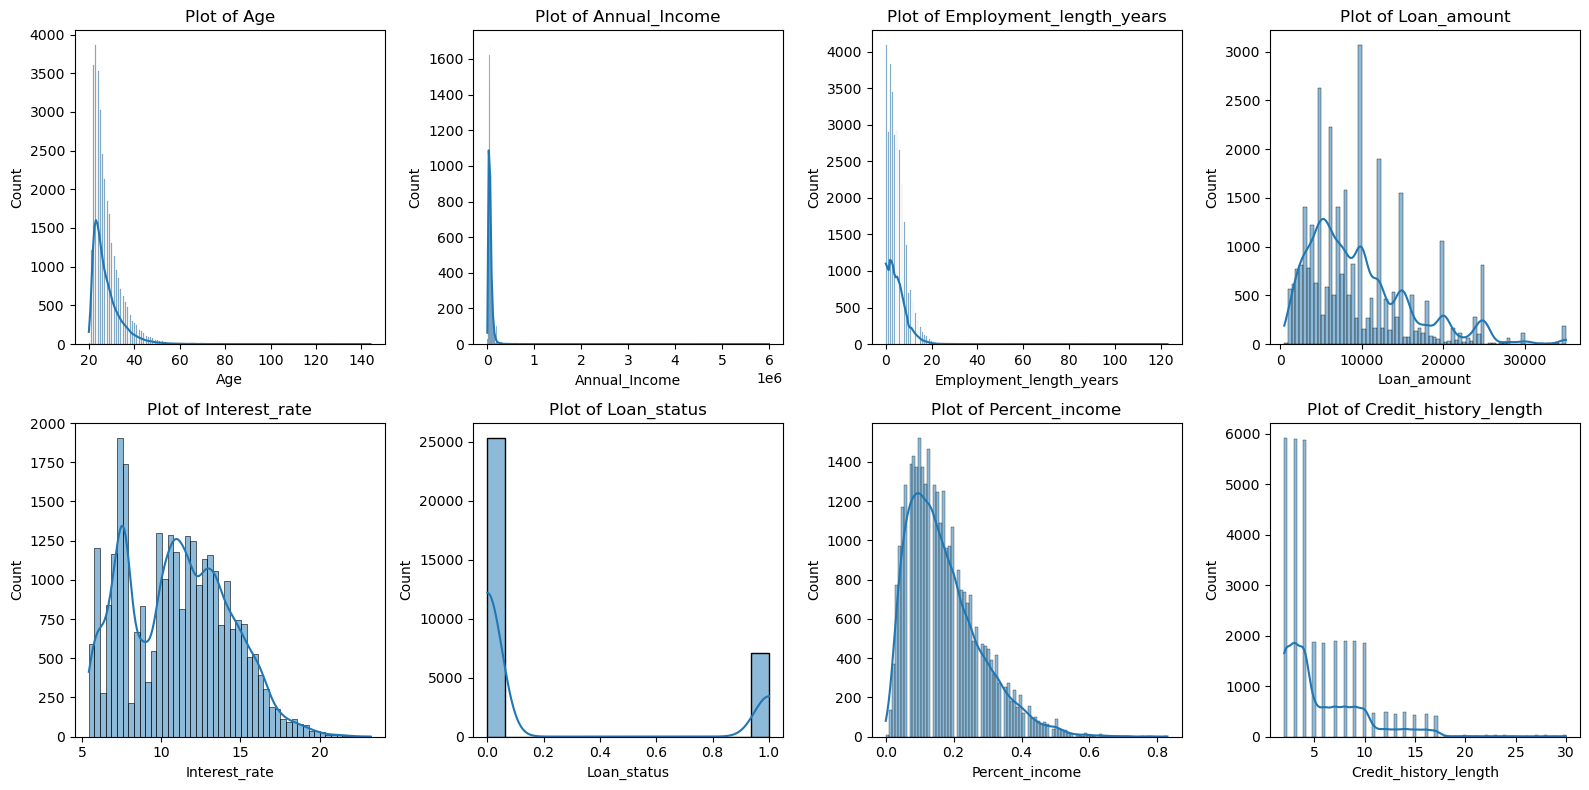

In [388]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axes = axes.flatten()

for ax, column in zip(axes, numerical.columns):
    sns.histplot(data=numerical, x=column, kde=True, ax=ax)
    ax.set_title(f"Plot of {column}")
    plt.tight_layout()

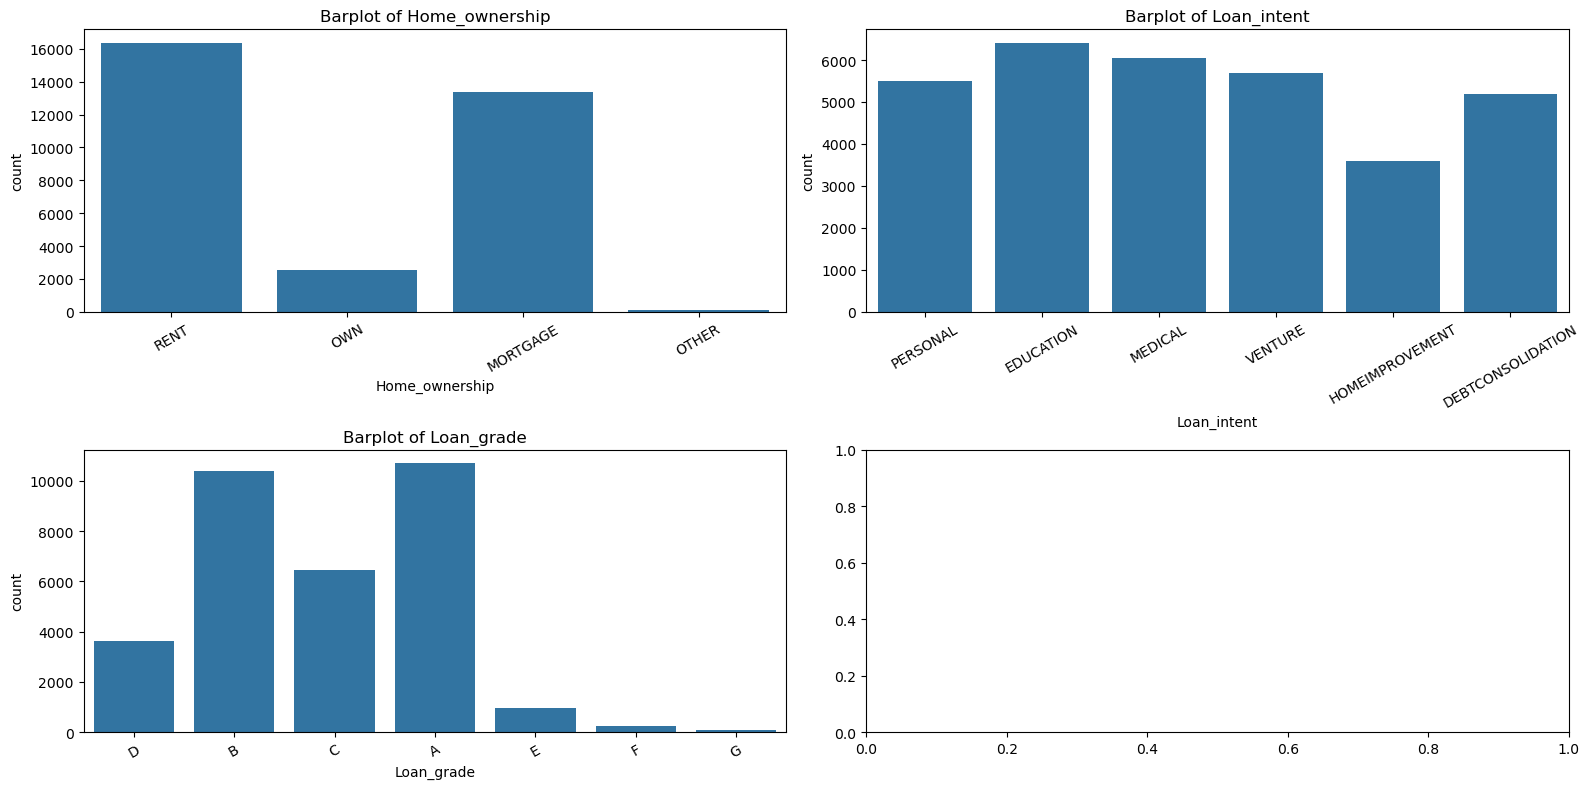

In [389]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(16,8))
axes = axes.flatten()

for ax, column in zip(axes, categorical.columns):
    sns.countplot(data=categorical, x=column, ax=ax)
    ax.set_title(f"Barplot of {column}")
    ax.tick_params(axis="x", labelrotation=30)
    plt.tight_layout()


In [390]:
numerical.shape

(32416, 8)

In [391]:
removed = (file["Age"] > 100) | (file["Employment_length_years"] > 62)
file = file[~removed].reset_index(drop=True)

In [414]:
# file = file.dropna()

In [393]:
median_ir = file['Interest_rate'].median()
file['Interest_rate'] = file['Interest_rate'].fillna(median_ir)

In [394]:
median_empl = file['Employment_length_years'].median()
file['Employment_length_years'] = file['Employment_length_years'].fillna(median_ir)

In [395]:
file.isna().sum()

Age                        0
Annual_Income              0
Home_ownership             0
Employment_length_years    0
Loan_intent                0
Loan_grade                 0
Loan_amount                0
Interest_rate              0
Loan_status                0
Percent_income             0
Historical_default         0
Credit_history_length      0
dtype: int64

In [396]:
le = LabelEncoder()
for categ in categorical:
    file[categ] = le.fit_transform(file[categ])

In [397]:
file

,Age,Annual_Income,Home_ownership,Employment_length_years,Loan_intent,Loan_grade,Loan_amount,Interest_rate,Loan_status,Percent_income,Historical_default,Credit_history_length
0,21,9600,2,5.0,1,1,1000,11.14,0,0.10,0,2
1,25,9600,0,1.0,3,2,5500,12.87,1,0.57,0,3
2,23,65500,3,4.0,3,2,35000,15.23,1,0.53,0,2
3,24,54400,3,8.0,3,2,35000,14.27,1,0.55,1,4
4,21,9900,2,2.0,5,0,2500,7.14,1,0.25,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...
32404,57,53000,0,1.0,4,2,5800,13.16,0,0.11,0,30
32405,54,120000,0,4.0,4,0,17625,7.49,0,0.15,0,19
32406,65,76000,3,3.0,2,1,35000,10.99,1,0.46,0,28
32407,56,150000,0,5.0,4,1,15000,11.48,0,0.10,0,26


In [398]:
file['Loan_to_Income_Ratio'] = file['Loan_amount'] / (file['Annual_Income'] + 1e-5)
file['Estimated_Interest_Cost'] = file['Loan_amount'] * (file['Interest_rate'] / 100)
file['Employment_to_Age_Ratio'] = file['Employment_length_years'] / (file['Age'] + 1e-5)
file['Income_Per_Age'] = file['Annual_Income'] / (file['Age'] + 1e-5)
file['Risk_Exposure_Score'] = file['Loan_amount'] * file['Interest_rate']

In [419]:
file

,Age,Annual_Income,Home_ownership,Employment_length_years,Loan_intent,Loan_grade,Loan_amount,Interest_rate,Loan_status,Percent_income,Historical_default,Credit_history_length,Loan_to_Income_Ratio,Estimated_Interest_Cost,Employment_to_Age_Ratio,Income_Per_Age,Risk_Exposure_Score
0,21,9600,2,5.0,1,1,1000,11.14,0,0.10,0,2,0.104167,111.4000,0.238095,457.142639,11140.00
1,25,9600,0,1.0,3,2,5500,12.87,1,0.57,0,3,0.572917,707.8500,0.040000,383.999846,70785.00
2,23,65500,3,4.0,3,2,35000,15.23,1,0.53,0,2,0.534351,5330.5000,0.173913,2847.824849,533050.00
3,24,54400,3,8.0,3,2,35000,14.27,1,0.55,1,4,0.643382,4994.5000,0.333333,2266.665722,499450.00
4,21,9900,2,2.0,5,0,2500,7.14,1,0.25,0,2,0.252525,178.5000,0.095238,471.428347,17850.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32404,57,53000,0,1.0,4,2,5800,13.16,0,0.11,0,30,0.109434,763.2800,0.017544,929.824398,76328.00
32405,54,120000,0,4.0,4,0,17625,7.49,0,0.15,0,19,0.146875,1320.1125,0.074074,2222.221811,132011.25
32406,65,76000,3,3.0,2,1,35000,10.99,1,0.46,0,28,0.460526,3846.5000,0.046154,1169.230589,384650.00
32407,56,150000,0,5.0,4,1,15000,11.48,0,0.10,0,26,0.100000,1722.0000,0.089286,2678.570950,172200.00


In [399]:
X = file.drop(columns="Loan_status")
Y = file['Loan_status']

In [400]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, stratify=Y,random_state=42)

In [401]:
sc = StandardScaler()
X_train_transform = sc.fit_transform(X_train)

In [402]:
smote = SMOTE(random_state=42, sampling_strategy=0.5)
X_train_sm, Y_train_sm = smote.fit_resample(X_train_transform, Y_train)
X_test_transform = sc.transform(X_test)

In [403]:
LogRegModel = LogisticRegression(C=1, solver='lbfgs', max_iter=2000)
LogRegModel.fit(X_train_sm, Y_train_sm)

LogisticRegression(C=1, max_iter=2000)

In [404]:
RDM_Forest = RandomForestClassifier(class_weight='balanced',n_estimators=100, min_samples_split=10,  min_samples_leaf=3, random_state=42)
RDM_Forest.fit(X_train, Y_train)

RandomForestClassifier(class_weight='balanced', min_samples_leaf=3,
                       min_samples_split=10, random_state=42)

In [405]:
scale_pos = (Y_train == 0).sum() / (Y_train == 1).sum()
XGB = XGBClassifier(n_estimators=600, booster='gbtree', subsample=0.8, scale_pos_weight=scale_pos, random_state=42)
XGB.fit(X_train, Y_train)

XGBClassifier(base_score=None, booster='gbtree', callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=600, n_jobs=None,
              num_parallel_tree=None, random_state=42, ...)

In [406]:
predictions_RDM_F = RDM_Forest.predict_proba(X_test)[:,1]
predictions_RDM_F = (predictions_RDM_F >= 0.33).astype(int)

In [407]:
predictions_XGB = XGB.predict_proba(X_test)[:,1]
predictions_XGB = (predictions_XGB >= 0.33).astype(int)

In [408]:
predictions_LGREG = LogRegModel.predict_proba(X_test_transform)[:,1]
predictions_LGREG = (predictions_LGREG >= 0.33).astype(int)

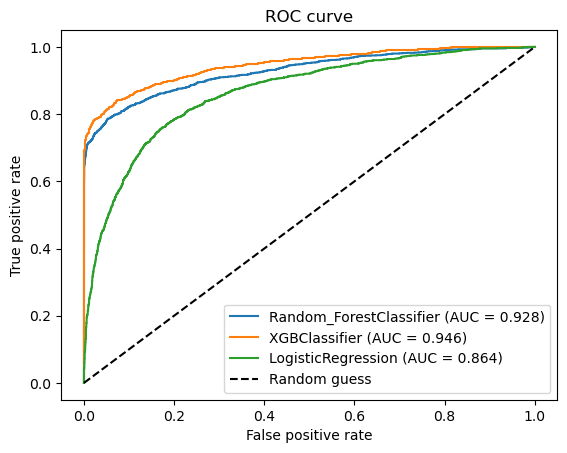

In [409]:
models = {"Random_ForestClassifier": RDM_Forest, "XGBClassifier":XGB, "LogisticRegression":LogRegModel}

for name, model in models.items():
    if name == 'LogisticRegression':
        proba = model.predict_proba(X_test_transform)[:,1]
    else:
        proba = model.predict_proba(X_test)[:,1]

    fpr, tpr, _ = roc_curve(Y_test, proba)
    auc = roc_auc_score(Y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.show()


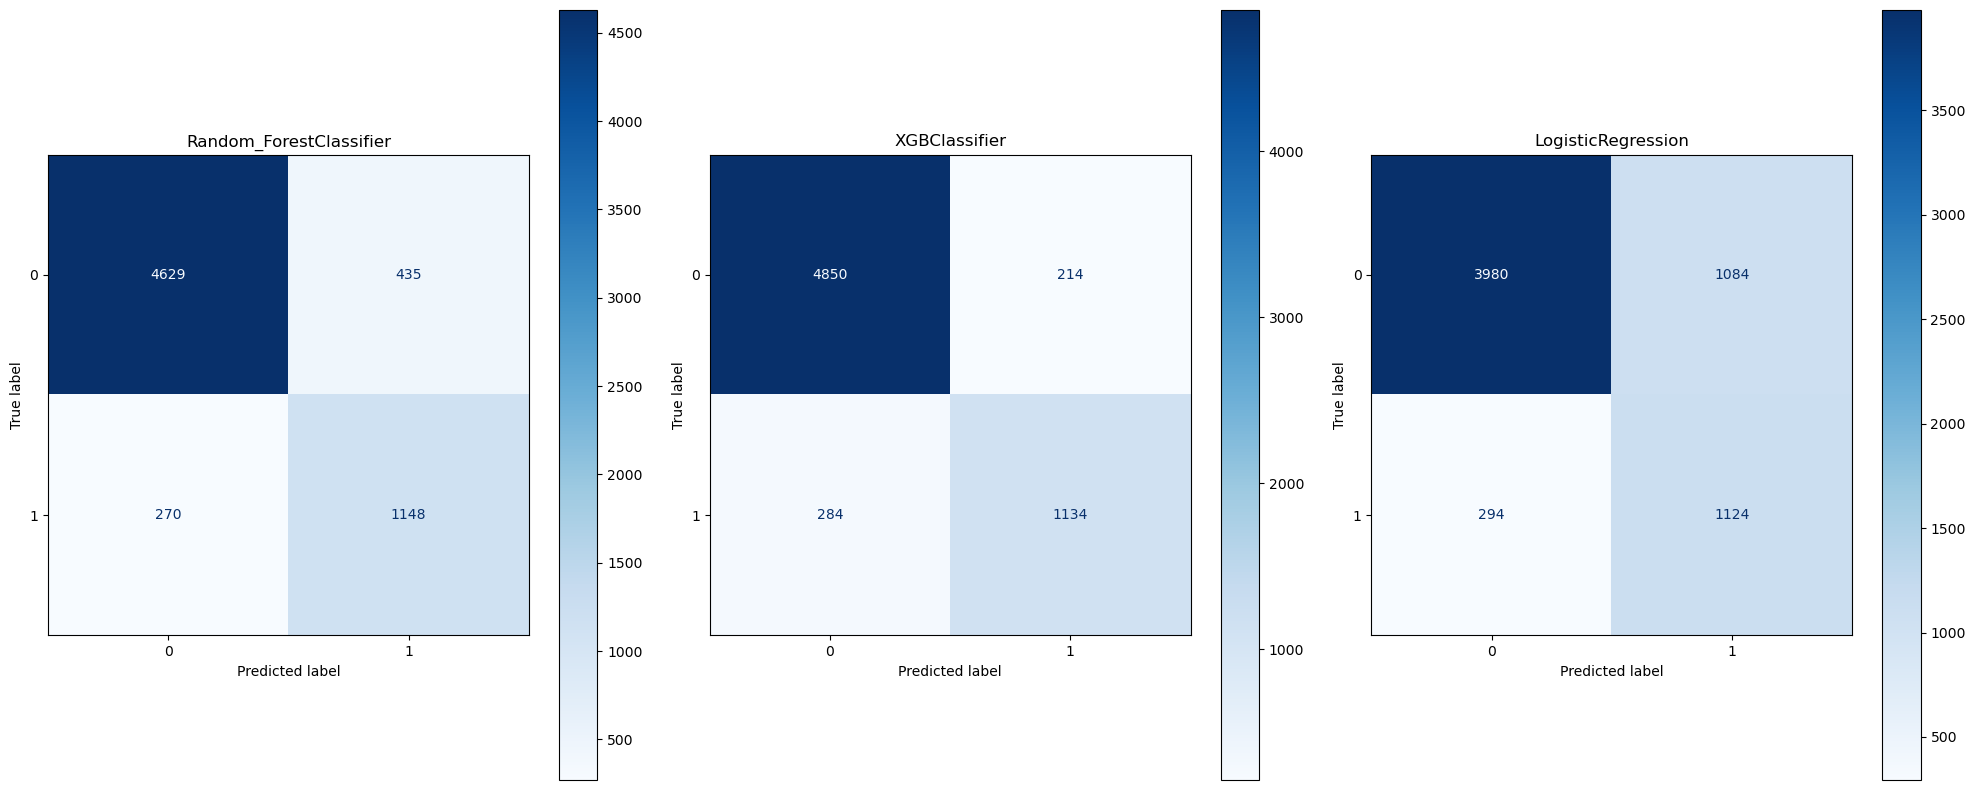

In [421]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1,3, figsize=(20, 8))
for ax, (name, model) in zip(axes, models.items()):
    if name == 'LogisticRegression':
        pred = model.predict_proba(X_test_transform)[:,1]                  
        pred = (pred >= 0.33).astype(int)   
    else: 
        pred = model.predict_proba(X_test)[:,1]                  
        pred = (pred >= 0.33).astype(int)
    ConfusionMatrixDisplay.from_predictions(Y_test, pred, ax=ax, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [411]:
print(classification_report(Y_test, predictions_RDM_F))

              precision    recall  f1-score   support

           0       0.94      0.91      0.93      5064
           1       0.73      0.81      0.77      1418

    accuracy                           0.89      6482
   macro avg       0.84      0.86      0.85      6482
weighted avg       0.90      0.89      0.89      6482



In [412]:
print(classification_report(Y_test, predictions_XGB))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95      5064
           1       0.84      0.80      0.82      1418

    accuracy                           0.92      6482
   macro avg       0.89      0.88      0.89      6482
weighted avg       0.92      0.92      0.92      6482



In [413]:
print(classification_report(Y_test, predictions_LGREG))

              precision    recall  f1-score   support

           0       0.93      0.79      0.85      5064
           1       0.51      0.79      0.62      1418

    accuracy                           0.79      6482
   macro avg       0.72      0.79      0.74      6482
weighted avg       0.84      0.79      0.80      6482



XGBClassifier:
MSE: 7.68%
MAE: 7.68%
RMSE: 27.72%
RandomForestClassifier:
MSE: 10.88%
MAE: 10.88%
RMSE: 32.98%
LogisticRegression:
MSE: 21.26%
MAE: 21.26%
RMSE: 46.11%


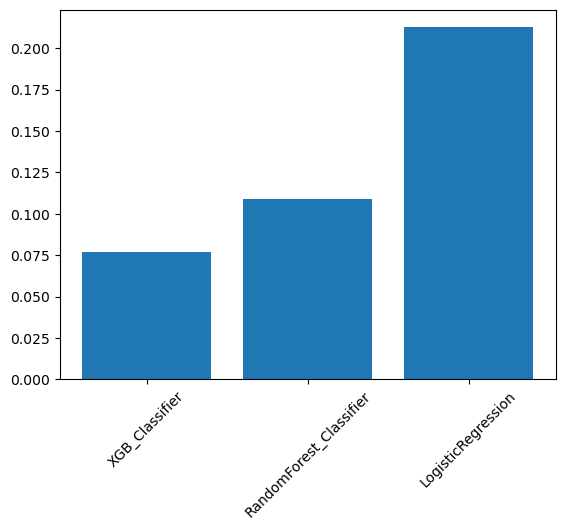

In [444]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

#mse
mse_xgbcl = mean_squared_error(Y_test, predictions_XGB)
mse_rfc = mean_squared_error(Y_test, predictions_RDM_F)
mse_lgreg = mean_squared_error(Y_test, predictions_LGREG)

#mae
mae_xgbcl = mean_absolute_error(Y_test, predictions_XGB)
mae_rfc = mean_absolute_error(Y_test, predictions_RDM_F)
mae_lgreg = mean_absolute_error(Y_test, predictions_LGREG)

#rmse
rmse_xgbcl = root_mean_squared_error(Y_test, predictions_XGB)
rmse_rfc = root_mean_squared_error(Y_test, predictions_RDM_F)
rmse_lgreg = root_mean_squared_error(Y_test, predictions_LGREG)

errors = {
    'XGBClassifier':{
        'MSE': mse_xgbcl,
        'MAE': mae_xgbcl,
        'RMSE': rmse_xgbcl,
    },

    'RandomForestClassifier':{
        'MSE': mse_rfc,
        'MAE': mae_rfc,
        'RMSE': rmse_rfc,
    },
    
    'LogisticRegression':{
        'MSE': mse_lgreg,
        'MAE': mae_lgreg,
        'RMSE': rmse_lgreg,
    }
}

for name,metrics in errors.items():
    print(f"{name}:")
    for metric, error in metrics.items():
        print(f"{metric}: {error*100:.2f}%")

plt.bar(['XGB_Classifier', 'RandomForest_Classifier', 'LogisticRegression'],[mse_xgbcl, mse_rfc, mse_lgreg])
plt.xticks(rotation=45)
plt.show()